In [1]:
import numpy as np
import torch 
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt
import math
import copy, io, contextlib

# Deep Hedging of an Equinox — Natixis × ENS Challenge Data (2020)

**Goal:** learn a weekly hedging strategy for a 5-year *Equinox* sold to a client, under transaction costs and a risk limit.

### The product
| | |
|---|---|
| Maturity $T$ | 5 years = 260 weeks |
| Reset date $R$ | 2.5 years = week 130 |
| Strike $K$, barrier $B$, spot $S_0$ | 1 |
| Rebate $G$ | 0.05 |

$$
\text{payoff} = \mathbf{1}_{\{S_R \ge B\}}\,G + \mathbf{1}_{\{S_R < B\}}\,(S_T-K)^+
$$

At the reset, either the product ends with the rebate $G$, or it becomes a call.

### The rules of the game
- **Delta hedge:** every week we choose a position $\theta_t$ in the underlying.
- **Vega hedge (imposed):** buy calls (5Y, $K=1$) at $t=0$ and at $t=R$.
- **Risk limit:** $\big|\Delta_{\text{book}}(t) + \theta_t\big| \le L$, for 3 limits $L \in \{0.1,\ 0.2,\ 0.5\}$.
- **Costs:** $10^{-4}$ on the underlying, $2\%$ of the price on options.
- **Score:** entropic risk of the hedged P&L, averaged over the 3 limits (lower is better).

### Framework
*Deep hedging* (Buehler, Gonon, Teichmann & Wood, 2019): parametrise the strategy with a neural network and minimise a risk measure of the final P&L directly over simulated paths.

$$
\min_{\theta \text{ adapted}} \ \rho\big(\text{PnL}(\theta)\big)
$$

*Adapted* = $\theta_t$ may only use information available at $t$ (no peeking into the future).

## 1. Data

- 25 000 simulated paths (supplementary file) + 5 000 official paths (validation file, used for the score).
- 261 weekly dates per path, $t = 0, \dots, 260$.
- Market model: stochastic volatility $\alpha_t$ and spot–vol correlation $\tanh(\lambda_t)$, under the **historical measure** (drift $\mu = -3\%$/year, *not* arbitrage-free).
- For each date: spot $S_t$, and Black–Scholes price / delta / vega of the Equinox (`auto*`) and of the hedging call (`vani*`).

We keep 7 features per date → tensors of shape `(N, 261, 7)`.

### 1.1 Data Import, Split and Visualisation

In [17]:
data = pd.read_csv('Supplementary Training Data (1).csv')
data = data.set_index("ID")

In [3]:
FEATURES = ('S', 'autoPrice', 'autoDelta', 'autoVega', 'vaniPrice', 'vaniDelta', 'vaniVega')

def split_features(df):
    """Return each feature's 261-point series as an (N, 261) array."""
    split = {}
    for name in FEATURES:
        columns = [f'{name}{t}' for t in range(261)]
        split[name] = df[columns]
    return split

split = split_features(data)
random_indices = np.random.randint(0, len(data), size=5)
split.keys()

dict_keys(['S', 'autoPrice', 'autoDelta', 'autoVega', 'vaniPrice', 'vaniDelta', 'vaniVega'])

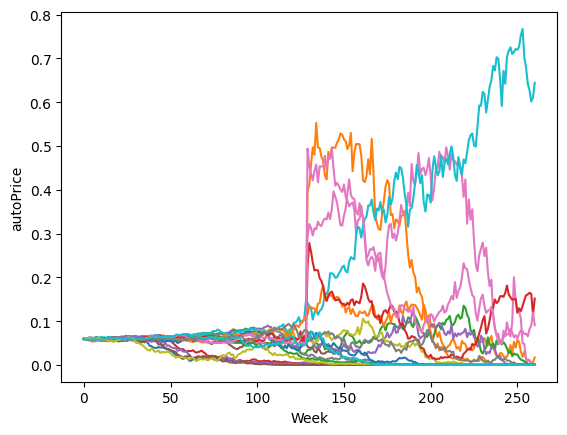

In [4]:
random_indices = np.random.randint(0, len(data), size=20)
plt.plot(np.arange(split['autoPrice'].shape[1]), split['autoPrice'].iloc[random_indices].T)
plt.xlabel("Week")
plt.ylabel("autoPrice")
plt.show()

### 1.2 Train/test split and tensors
- 80% of the supplementary paths for training, 20% to select the best epoch.
- Paths are i.i.d. simulations → a simple split is fine (no time ordering between paths).
- No targets: the loss is computed from the P&L the strategy generates.

In [5]:
from torch.utils.data import TensorDataset, DataLoader

# Train / Test split
train_id, test_ids = np.split(data.index, [int(0.8 * len(data))])
train_split = {name: df.loc[train_id] for name, df in split.items()}
test_split = {name: df.loc[test_ids] for name, df in split.items()}


def to_tensor(split_dict):
    arrays = [split_dict[name].to_numpy() for name in FEATURES]   # 7 arrays of (N, 261)
    return torch.tensor(np.stack(arrays, axis=-1), dtype=torch.float32)  # (N, 261, 7)

X_train = to_tensor(train_split)
X_test  = to_tensor(test_split)

train_loader = DataLoader(TensorDataset(X_train), batch_size=256, shuffle=True)

## 2. The hedging P&L

We are **short** the Equinox, **long** $\psi_t$ calls (vega hedge) and hold $\theta_t$ units of spot (delta hedge). The network only chooses $\theta_t$; $\psi_t$ is fixed by the rules.

$$
\text{PnL} = \underbrace{\sum_t \theta_t\,(S_{t+1}-S_t)}_{\text{delta hedge}}
\;+\; \underbrace{\text{calls}}_{\text{vega hedge}}
\;-\; \text{payoff} \;-\; \text{fees}
$$

All conventions below reproduce the scoring function (see section 6).

### 2.1 Vega hedge

Calls are bought at $t=0$ to cancel the Equinox vega, and topped up at $R$ only if the product is still alive ($\mathcal{V}^E$: Equinox vega, $\mathcal{V}^C$: call vega):

$$
\psi_t = \frac{\mathcal{V}^{E}_{0}}{\mathcal{V}^{C}_{0}} + \mathbf{1}_{\{t > 130,\; S_{130} < B\}} \left( \frac{\mathcal{V}^{E}_{130}}{\mathcal{V}^{C}_{130}} - \frac{\mathcal{V}^{E}_{0}}{\mathcal{V}^{C}_{0}} \right)
$$

In the data: $\psi_0 \approx 0.11$, and $\psi \approx 1$ after the reset (the Equinox has become a call).

The risk limit is centred on the **book delta** $\Delta^E_t - \psi_t\,\Delta^C_t$; following the scoring function, the allowed band is

$$
\big|\theta_t - c_t\big| \le L, \qquad c_t = -\big(\Delta^E_t - \psi_t\,\Delta^C_t\big)
$$

In [6]:
def vega_hedge(x: torch.Tensor) -> torch.Tensor:
    """Number of calls held at each week, shape (batch, 261)."""
    auto_vega = x[:, :, 3] #(batch, 261)
    vani_vega = x[:, :, 6] #(batch, 261)

    # Calls bought at week 0, and topped up at week 130 only if the product is still alive (S_130 < 1)
    psi_0   = auto_vega[:, 0]   / vani_vega[:, 0]
    psi_130 = auto_vega[:, 130] / vani_vega[:, 130]

    S = x[:, :, 0]
    below = S[:, 130] < 1.0                               # barrier B = 1
    psi_130 = torch.where(below, psi_130, psi_0)          # above the barrier: keep the week-0 calls

    psi = torch.empty_like(auto_vega)
    psi[:, :131] = psi_0.unsqueeze(1)                     # the scorer still uses the week-0 calls at week 130
    psi[:, 131:] = psi_130.unsqueeze(1)
    
    return psi


def band_center(x: torch.Tensor) -> torch.Tensor:
    """Centre of the allowed band for the spot position, shape (batch, 261).
    The scorer requires |theta - band_center| <= L, i.e. |theta + autoDelta - psi * vaniDelta| <= L."""
    psi = vega_hedge(x)
    return -(x[:, :, 2] - psi * x[:, :, 5])

### 2.2 Payoff

$$
\text{payoff} = \mathbf{1}_{\{S_{130} \ge B\}}\,G + \mathbf{1}_{\{S_{130} < B\}}\,(S_{260}-K)^+
$$

We write $a = \mathbf{1}_{\{S_{130} < B\}}$: the product is still **alive** after the reset.

In [ ]:
R, B, K, G = 130, 1.0, 1.0, 0.05      # reset index, barrier, strike, rebate (as in the scoring function)

def equinox_payoff(S: torch.Tensor) -> torch.Tensor:
    S_R, S_T = S[:, R], S[:, -1]
    return torch.where(S_R >= B, torch.full_like(S_T, G), torch.clamp(S_T - K, min=0.0))

### 2.3 P&L

$$
\text{PnL} = \sum_{t=0}^{130} \theta_t \Delta S_t + a \sum_{t=131}^{259} \theta_t \Delta S_t
\;+\; \psi_{260}(S_{260}-K)^+ - \psi_0 C_0 - (\psi_{260}-\psi_0)\,C_{130}
\;-\; \text{payoff} \;-\; \text{fees}
$$

- $\Delta S_t = S_{t+1} - S_t$; after the reset, the spot only counts if the product is alive.
- Calls are bought at $C_0$ and $C_{130}$ and held to maturity.
- Fees, as computed by the scoring function: $10^{-4}\sum_t |\text{cash}_t|$ with $\text{cash}_t = \sum_{s\le t}(\theta_s-\theta_{s-1})S_s$, plus $2\% \cdot \big(|\psi_0 C_0| + |\psi_{260}-\psi_0|\big)\,C_{130}$.

In [ ]:
SPOT_COST = 1e-4
OPTION_COST = 0.02

def hedging_pnl(x, theta):
    """P&L exactly as computed by the scoring function in Natixis.ipynb. Returns shape (batch,).
    Score for one limit = log mean exp(-pnl)."""
    S          = x[:, :, 0]
    vani_price = x[:, :, 4]
    psi = vega_hedge(x)

    # spot gains: weeks 0..130 always, weeks 131..259 only if the product is still alive
    alive = (S[:, R] < B).float()                        # 1: product continues, 0: ended (same test as equinox_payoff)
    dS = S.diff(dim=1)                                   # dS[:, t] = S[t+1] - S[t]
    spot_gains = (theta[:, :131] * dS[:, :131]).sum(dim=1) \
               + alive * (theta[:, 131:260] * dS[:, 131:260]).sum(dim=1)

    # calls held to maturity: bought at P0 (week 0) and P130 (week 130), each pays (S_260 - K)+
    psi_0, psi_end = psi[:, 0], psi[:, -1]
    P0, P130 = vani_price[:, 0], vani_price[:, R]
    call_T = torch.clamp(S[:, -1] - K, min=0.0)
    call_gains = psi_end * call_T - psi_0 * P0 - (psi_end - psi_0) * P130

    # fees, computed like the scoring function (spot: charged every week on the running cash spent)
    d_theta = torch.diff(theta[:, :260], dim=1, prepend=torch.zeros_like(theta[:, :1]))
    cash = torch.cumsum(d_theta * S[:, :260], dim=1)
    spot_fees = SPOT_COST * (cash[:, :131].abs().sum(dim=1) + alive * cash[:, 131:260].abs().sum(dim=1))
    option_fees = OPTION_COST * ((psi_0 * P0).abs() + (psi_end - psi_0).abs()) * P130
    costs = spot_fees + option_fees

    payoff = equinox_payoff(S)
    return - payoff + spot_gains + call_gains - costs

## 3. The strategy: an LSTM

$$
\theta_t = c_t + L \tanh\big(f(h_t)\big), \qquad h_t = \text{LSTM}(x_0, \dots, x_t)
$$

- **Adapted by construction:** $h_t$ only sees the past (checked in section 5).
- **Risk limit by construction:** $\tanh \in (-1, 1)$, so $|\theta_t - c_t| < L$ on every path, every week.
- **One network for all weeks:** weights are shared through time; the LSTM gates limit vanishing gradients over 261 steps.
- **Initialisation:** output bias at $-3$, so training starts near the constant hedge $\theta_t = c_t - L$ (see section 5).

In [8]:
class LSTMRegressor(nn.Module):
    def __init__(self, input_dim=7, hidden_dim=32, num_layers=1, output_dim=1, L=1.0):
        super().__init__()
        self.L = L
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.head = nn.Linear(hidden_dim, output_dim)

        nn.init.zeros_(self.head.weight)
        nn.init.constant_(self.head.bias, -3.0)   # tanh(-3) ~ -0.995: start at the constant -L hedge

    def forward(self, x):
        # x: (batch_size, seq_len, input_dim)
        out, _ = self.lstm(x)                                   # (batch, 261, hidden_dim), causal
        r = self.L * torch.tanh(self.head(out)).squeeze(-1)     # learned deviation, in (-L, L)
        return band_center(x) + r                               # spot position, always inside the band

## 4. Training

**Loss: entropic risk**, the score of the challenge ($\lambda = 1$):

$$
\rho(\text{PnL}) = \frac{1}{\lambda}\log \mathbb{E}\big[e^{-\lambda\,\text{PnL}}\big]
$$

- Minimising $\rho$ ⇔ maximising the exponential utility $\mathbb{E}\big[-e^{-\lambda\,\text{PnL}}\big]$.
- Losses weigh more than gains; for small $\lambda$: $\rho \approx -\mathbb{E}[\text{PnL}] + \tfrac{\lambda}{2}\mathrm{Var}[\text{PnL}]$.
- In money units: $\rho$ is the certainty-equivalent cost of the hedged position.
- Computed with `logsumexp` for numerical stability.

One model per limit $L$; Adam, gradient clipping, and we keep the epoch with the best validation loss.

In [18]:
LAMBDA = 1.0     # the score is log mean exp(-pnl)

def entropic_loss(pnl, lam=LAMBDA):
    """(1/lam) * log E[exp(-lam * pnl)], estimated over the batch."""
    z = -lam * pnl
    return (torch.logsumexp(z, dim=0) - math.log(pnl.shape[0])) / lam

@torch.no_grad()
def evaluate(model, X):
    model.eval()
    pnl = hedging_pnl(X, model(X))
    return entropic_loss(pnl).item(), pnl.mean().item(), pnl.std().item()

def train(model, train_loader, X_val, optimizer, num_epochs=10, device="cpu"):
    model.to(device)
    X_val = X_val.to(device)
    history = []
    best_loss, best_state = float("inf"), None

    for epoch in range(num_epochs):
        model.train()
        total_loss, n = 0.0, 0

        for (x,) in train_loader:
            x = x.to(device)
            theta = model(x)
            pnl = hedging_pnl(x, theta)
            loss = entropic_loss(pnl)  # Use logsumexp for numerical stability

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item() * len(x)
            n += len(x)

        val_loss, val_mean, val_std = evaluate(model, X_val)
        history.append((total_loss / n, val_loss))
        if val_loss < best_loss:
            best_loss, best_state = val_loss, copy.deepcopy(model.state_dict())
        
        print(f"epoch {epoch+1:2d}  train={total_loss/n:.5f}  val={val_loss:.5f}  "
              f"mean={val_mean:+.4f}  std={val_std:.4f}")

    model.load_state_dict(best_state)              # keep the best epoch, not the last
    return history

neutral_test = band_center(X_test)
print("benchmark (r = 0):", entropic_loss(hedging_pnl(X_test, neutral_test)).item())

models, histories = {}, {}
for L in (0.1, 0.2, 0.5):
    print(f"\n===== L = {L} =====")
    print("constant -L:", entropic_loss(hedging_pnl(X_test, neutral_test - L)).item())
    torch.manual_seed(0)
    model = LSTMRegressor(L=L)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    histories[L] = train(model, train_loader, X_test, optimizer, num_epochs=10)
    models[L] = model

benchmark (r = 0): 0.07955169677734375

===== L = 0.1 =====
constant -L: 0.0693960189819336


KeyboardInterrupt: 

## 5. Evaluation

Two baselines, both inside the risk limit:
- **benchmark** $\theta_t = c_t$ (hedge the book delta, $r = 0$),
- **constant** $\theta_t = c_t - L$ (always at the short edge of the band).

Metrics on held-out paths: entropic risk (the score), mean, std, $\text{CVaR}_{5\%}$ and mean replication cost $= -\mathbb{E}[\text{PnL}]$.

In [10]:
def summary(name, pnl):
    q05 = torch.quantile(pnl, 0.05)
    cvar = -pnl[pnl <= q05].mean()              # average loss on the worst 5% of paths
    return dict(hedge=name,
                entropic=entropic_loss(pnl).item(),
                mean=pnl.mean().item(),
                std=pnl.std().item(),
                CVaR5=cvar.item(),
                repl_cost=(-pnl).mean().item())   # = payoff - gains + costs

rows = [summary("benchmark (r = 0)", hedging_pnl(X_test, neutral_test))]
pnls = {}
with torch.no_grad():
    for L, m in models.items():
        rows.append(summary(f"constant -{L}", hedging_pnl(X_test, neutral_test - L)))
        pnls[L] = hedging_pnl(X_test, m(X_test))
        rows.append(summary(f"LSTM L={L}", pnls[L]))

pd.DataFrame(rows).set_index("hedge").round(4)

,entropic,mean,std,CVaR5,repl_cost
hedge,,,,,
benchmark (r = 0),0.0796,-0.0765,0.0782,0.2498,0.0765
constant -0.1,0.0694,-0.0660,0.0815,0.2524,0.0660
LSTM L=0.1,0.0694,-0.0660,0.0815,0.2524,0.0660
constant -0.2,0.0616,-0.0569,0.0970,0.2687,0.0569
LSTM L=0.2,0.0616,-0.0569,0.0970,0.2687,0.0569
constant -0.5,0.0459,-0.0305,0.1761,0.3774,0.0305
LSTM L=0.5,0.0459,-0.0305,0.1761,0.3774,0.0305


### 5.1 P&L distributions

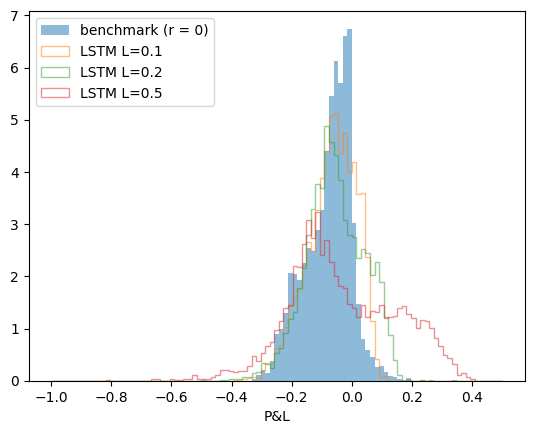

In [11]:
bins = np.linspace(-1.0, 0.5, 100)
plt.hist(hedging_pnl(X_test, neutral_test).numpy(), bins, alpha=.5, density=True, label="benchmark (r = 0)")
for L, p in pnls.items():
    plt.hist(p.numpy(), bins, alpha=.5, density=True, histtype="step", lw=2, label=f"LSTM L={L}")
plt.xlabel("P&L"); plt.legend(); plt.show()

### 5.2 What did the network learn?
Learned deviation $r_t = \theta_t - c_t$, against the spot before the reset and over time.

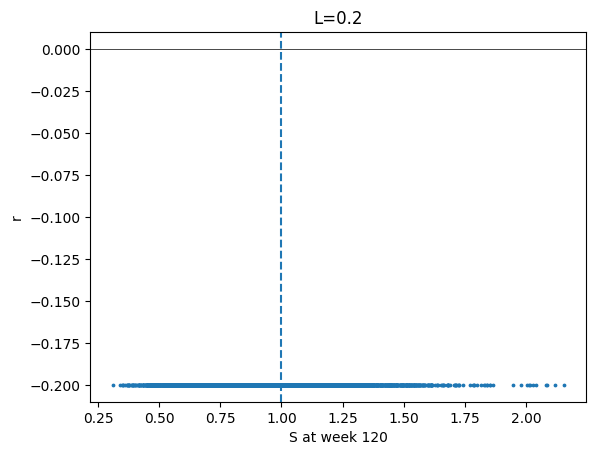

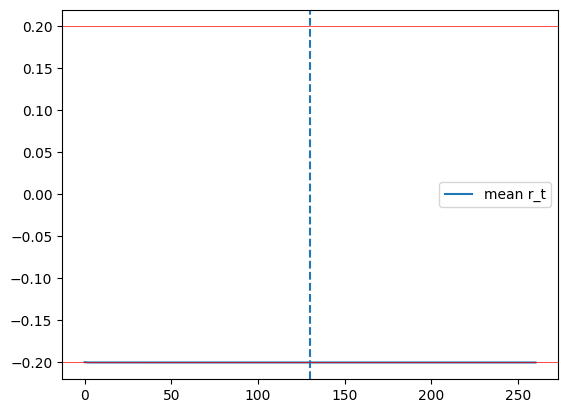

In [12]:
with torch.no_grad():
    L = 0.2; m = models[L]
    r = m(X_test) - neutral_test                 # learned deviation from the band centre
    t = 120                                      # a few weeks before the reset
    plt.scatter(X_test[:, t, 0], r[:, t], s=3)
    plt.axvline(1.0, ls="--"); plt.axhline(0, c="k", lw=.5)
    plt.xlabel(f"S at week {t}"); plt.ylabel("r"); plt.title(f"L={L}"); plt.show()

    plt.plot(r.mean(0), label="mean r_t"); plt.axvline(130, ls="--")
    plt.axhline(-L, c="r", lw=.5); plt.axhline(L, c="r", lw=.5); plt.legend(); plt.show()

### 5.3 Sanity checks
- Risk limit: $\max |r_t| < L$.
- Adaptedness: changing the path after week 200 must not change $\theta_t$ before week 200.

In [13]:
with torch.no_grad():
    for L, m in models.items():
        r = m(X_test) - neutral_test
        x2 = X_test[:100].clone(); x2[:, 200:] += 1.0
        causal = torch.allclose(m(X_test[:100])[:, :200], m(x2)[:, :200])
        print(f"L={L}: max|r|={r.abs().max():.4f} < {L}  causal={causal}")

L=0.1: max|r|=0.1000 < 0.1  causal=True
L=0.2: max|r|=0.2000 < 0.2  causal=True
L=0.5: max|r|=0.5000 < 0.5  causal=True


### 5.4 Takeaways

| | L = 0.1 | L = 0.2 | L = 0.5 | **average** |
|---|---|---|---|---|
| benchmark ($r=0$) | 0.0782 | 0.0782 | 0.0782 | 0.0782 |
| constant ($r=-L$) | 0.0685 | 0.0612 | 0.0471 | **0.0589** |
| LSTM | 0.0685 | 0.0612 | 0.0471 | **0.0589** |

*Official validation file, 5 000 paths. Platform score: 0.0597 for both submissions.*

- **The LSTM learns the constant hedge $r_t \approx -L$.** It beats the benchmark by ≈ 25%, but not the constant.
- **Why:** the paths have a negative drift ($\mu = -3\%$), so a short position earns money on average. With exponential utility the optimal tilt is $\mu / (\lambda\sigma^2) \approx -0.75$, outside every band → the limit binds and the best policy sits at $-L$.
- **The rest is hard to hedge:** the main risk is the jump at the reset (rebate vs call) and the imposed vega hedge, which cannot be offset within $|r| \le L$.
- Extra information (volatility $\alpha_t$, reset proximity) did not beat the constant hedge in our tests.

## 6. Check against the scoring function

On the platform, the constant $-L$ hedge scored **0.0597**; this function gives 0.0589 on all 5 000 paths (consistent with the platform scoring a subset of paths).

In [19]:
import numpy as np
import pandas as pd


def PreparationScore(datasetValidation, reducedsoumissionDelta, nbscenarios):
    nbDates = 261
    S = np.zeros((nbscenarios, nbDates))
    vanillePrice = np.zeros((nbscenarios, nbDates))
    vanilleDelta = np.zeros((nbscenarios, nbDates))
    vanilleVega = np.zeros((nbscenarios, nbDates))
    autocallDelta = np.zeros((nbscenarios, nbDates))
    autocallVega = np.zeros((nbscenarios, nbDates))

    S[:, :] = datasetValidation[:, :nbDates]
    vanillePrice[:, :] = datasetValidation[:, 6*nbDates:7*nbDates]
    vanilleDelta[:, :] = datasetValidation[:, 7*nbDates:8*nbDates]
    vanilleVega[:, :] = datasetValidation[:, 8*nbDates:9*nbDates]
    autocallDelta[:, :] = datasetValidation[:, 4*nbDates:5*nbDates]
    autocallVega[:, :] = datasetValidation[:, 5*nbDates:6*nbDates]

    Barrier = 1
    nb0Vanille = np.zeros((nbscenarios))
    nb1Vanille = np.zeros((nbscenarios))
    nb0Vanille[:] = autocallVega[:, 0] / vanilleVega[:, 0]
    AutocallVegaCorrected130 = autocallVega[:, 130] - nb0Vanille[:] * vanilleVega[:, 130]
    mask_below_barrier = S[:, 130] < Barrier
    nb1Vanille[mask_below_barrier] = AutocallVegaCorrected130[mask_below_barrier] / vanilleVega[mask_below_barrier, 130]
    return reducedsoumissionDelta, autocallDelta, autocallVega, vanilleDelta, vanilleVega, nb0Vanille, nb1Vanille, vanillePrice, S


def ControlLimits(soumissionDelta, autocallDelta, autocallVega, vanilleDelta, vanilleVega, nb0Vanille, nb1Vanille, nbscenarios,lim):
    LimitRespected = True
    limites = lim
    epsilon = 0.001
    nblim = len(lim)
    nbDates = 261
    AutocallVegaCorrected = np.zeros((nbscenarios, nbDates))
    TotalDelta = np.zeros((nbscenarios, nbDates))
    reshaped_nb0Vanille = nb0Vanille.reshape((nbscenarios, 1))
    reshaped_nb1Vanille = nb1Vanille.reshape((nbscenarios, 1))
    TotalDelta[:, :131] = autocallDelta[:, :131] - reshaped_nb0Vanille * vanilleDelta[:, :131]
    for iLimit in range(nblim):
        print("max:",np.max(abs(soumissionDelta[:, iLimit * nbDates:iLimit * nbDates + 131] + TotalDelta[:, :131])))
        if (abs(soumissionDelta[:, iLimit * nbDates:iLimit * nbDates + 131] + TotalDelta[:, :131]) > (limites[iLimit] + epsilon)).any():
            LimitRespected = False
    print("OK ")
    TotalDelta[:, 131:nbDates] = autocallDelta[:, 131:nbDates] - (reshaped_nb0Vanille + reshaped_nb1Vanille) * vanilleDelta[:, 131:nbDates]
    for iLimit in range(nblim):
        print("max:",np.max(abs(soumissionDelta[:, 131 + iLimit * nbDates:nbDates + iLimit * nbDates] + TotalDelta[:, 131:nbDates])))
        if (abs(soumissionDelta[:, 131 + iLimit * nbDates:nbDates + iLimit * nbDates] + TotalDelta[:, 131:nbDates]) > limites[iLimit] + epsilon).any():
            LimitRespected = False
    return LimitRespected


def CalculScore(soumissionDelta, nb0Vanille, nb1Vanille, vanillePrice, S, nbscenarios,lim):
    CDelta = 0.0001
    CVega = 0.02
    nbDates = 261
    Barrier = 1
    strike = 1
    rebate = 0.05
    nblim = len(lim)
    payoff = np.zeros((nbscenarios))
    hedgeBenefit = np.zeros((nblim, nbscenarios))
    vegahedgePayoff = np.zeros((nblim, nbscenarios))
    transacDeltaCost = np.zeros((nblim, nbscenarios))
    transacVegaCost = np.zeros((nblim, nbscenarios))
    achatsDeltaCost = np.zeros((nblim, nbscenarios))
    AutocallFlag = np.zeros((nbscenarios))

    mask_S_below_barrier = S[:, 130] <= Barrier
    payoff[mask_S_below_barrier] = np.maximum(S[mask_S_below_barrier, 260] - strike, 0)
    AutocallFlag[mask_S_below_barrier] = 1
    payoff[~mask_S_below_barrier] = rebate
    AutocallFlag[~mask_S_below_barrier] = 0

    price = np.zeros((nblim))
    for iLimit in range(nblim):
        # determination des hedge limites
        # calcul du pay-off de l'equinoxe

        # calcul du cout de hedge
        hedgeBenefit[iLimit, :] += np.sum(soumissionDelta[:, iLimit * nbDates:iLimit * nbDates + 131] * (S[:, 1:132] - S[:, :131]), axis=1)
        for idate in range(131):
            # calcul du delta acheté
            if (idate == 0):
                achatDelta = soumissionDelta[:, idate + iLimit * nbDates]
            else:
                achatDelta = (soumissionDelta[:, idate + iLimit * nbDates] - soumissionDelta[:,
                                                                             idate + iLimit * nbDates - 1])
            # calcul impact tresorerie des achat de delta
            achatsDeltaCost[iLimit, :] += achatDelta * S[:, idate]
            # calcul des couts de transactions en delta
            transacDeltaCost[iLimit, :] += abs(achatsDeltaCost[iLimit, :])

        hedgeBenefit[iLimit, :] += np.sum(AutocallFlag[:].reshape(nbscenarios,1) * soumissionDelta[:, 131 + iLimit * nbDates:(nbDates-1) + iLimit * nbDates] * (S[:, 132:nbDates] - S[:, 131:nbDates-1]), axis=1)
        for idate in range(131, nbDates - 1):
            # calcul du delta acheté
            if (idate == 0):
                achatDelta = soumissionDelta[:, idate + iLimit * nbDates]
            else:
                achatDelta = (soumissionDelta[:, idate + iLimit * nbDates] - soumissionDelta[:,
                                                                             idate + iLimit * nbDates - 1])
            # calcul impact tresorerie des achat de delta
            achatsDeltaCost[iLimit, :] += achatDelta * S[:, idate]
            # calcul des couts de transactions en delta
            transacDeltaCost[iLimit, :] += AutocallFlag[:] * abs(achatsDeltaCost[iLimit, :])

        # calcul du payoff du au vegahedge
        vegahedgePayoff[iLimit, :] = \
            (nb0Vanille[:] + nb1Vanille[:]) * np.maximum(S[:, 260] - strike, 0) * AutocallFlag[:] \
            + nb0Vanille[:] * np.maximum(S[:, 260] - strike, 0) * (1 - AutocallFlag[:]) \
            - nb0Vanille[:] * vanillePrice[:, 0] - nb1Vanille[:] * vanillePrice[:, 130]
        # calcul du cout des transactions en vega
        transacVegaCost[iLimit, :] = (abs(nb0Vanille[:] * vanillePrice[:, 0]) + abs(nb1Vanille[:])) * vanillePrice[:,130]
        # calcul de l'utility function traduite en prix (pris dans
        # Deep Hedging Swissquote Conference 2018 on Machine Learning in Finance Geneva, Nov 9th 2018 by Dr. Hans Buehler, adapté au vega hedge)
        price[iLimit] = np.log(
            np.mean(
                np.exp(
                    -(hedgeBenefit[iLimit, :] - payoff[:] + vegahedgePayoff[iLimit, :]
                      - transacDeltaCost[iLimit, :] * CDelta - transacVegaCost[iLimit, :] * CVega)
                )
            )
        )
    score = np.mean(price)
    all_ =  -(hedgeBenefit[iLimit, :] - payoff[:] + vegahedgePayoff[iLimit, :]- transacDeltaCost[iLimit, :] * CDelta - transacVegaCost[iLimit, :] * CVega)
    return score,all_


def scoring(reducedsoumissionDelta, datasetValidation, nbscenarios,lim):
    reducedsoumissionDelta, autocallDelta, autocallVega, vanilleDelta, vanilleVega, nb0Vanille, nb1Vanille, vanillePrice, S = PreparationScore(
        datasetValidation, reducedsoumissionDelta, nbscenarios)
    if ControlLimits(reducedsoumissionDelta, autocallDelta, autocallVega, vanilleDelta, vanilleVega, nb0Vanille,
                     nb1Vanille, nbscenarios,lim):
        score = CalculScore(reducedsoumissionDelta, nb0Vanille, nb1Vanille, vanillePrice, S, nbscenarios,lim)
    else:
        score = 100000
    return score


def scoringFromDataFrame(Validation,submissiondataframe,lim):
    validationdataframe = Validation
    reducedsoumissionDelta = submissiondataframe.values
    index_traj = submissiondataframe.index.values
    nbscenarios = len(index_traj)
    XdatasetValidation = validationdataframe.iloc[index_traj].values[0:, 0:]
    score = scoring(reducedsoumissionDelta, XdatasetValidation, nbscenarios,lim)
    return score

In [15]:
val = pd.read_csv('Challenge Data Validation.csv')
X_val = torch.tensor(np.stack([val[[f'{n}{t}' for t in range(261)]].to_numpy() for n in FEATURES], -1),
                     dtype=torch.float32)
V = val.drop(columns='ID').values
neutral_val = band_center(X_val)

def official(theta, L):
    with contextlib.redirect_stdout(io.StringIO()):          # the scoring function prints a lot
        return scoring(theta.double().numpy(), V, len(V), [L])[0]

rows = []
with torch.no_grad():
    for L, m in models.items():
        for name, th in [("constant -L", neutral_val - L * (1 - 1e-4)), ("LSTM", m(X_val))]:
            rows.append(dict(L=L, hedge=name,
                             ours=entropic_loss(hedging_pnl(X_val, th)).item(),
                             official=official(th, L)))
res = pd.DataFrame(rows)
print(res.round(6))
print(res.groupby("hedge")[["ours", "official"]].mean().round(6))     # score = average over the 3 limits

     L        hedge      ours  official
0  0.1  constant -L  0.068492  0.068492
1  0.1         LSTM  0.068491  0.068491
2  0.2  constant -L  0.061207  0.061207
3  0.2         LSTM  0.061207  0.061206
4  0.5  constant -L  0.047063  0.047063
5  0.5         LSTM  0.047062  0.047061
                 ours  official
hedge                          
LSTM         0.058920  0.058919
constant -L  0.058921  0.058920


## 7. Submission

One row per path (`ID`), then $\theta_t$ for $t = 0, \dots, 260$ for each limit: `L1date0 … L1date260, L2date0 …, L3date260`.

In [16]:
template = pd.read_csv('Challenge Data Validation (1).csv')          # ID + L1date0 ... L3date260, zeros
assert template.ID.tolist() == val.ID.tolist()
submission = template.astype({c: float for c in template.columns[1:]})

with torch.no_grad():
    for label, L in zip(("L1", "L2", "L3"), (0.1, 0.2, 0.5)):
        theta = models[L](X_val).double()
        assert (theta - band_center(X_val.double())).abs().max() < L, f"{label} outside the limit"
        submission[[f'{label}date{t}' for t in range(261)]] = theta.numpy()

submission.to_csv('submission_lstm_entropic.csv', index=False, float_format='%.10f')
print(submission.shape)

(5000, 784)
